In [5]:
# imports
import json
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import imageio.v3 as iio

In [ ]:
def perpendicular(v):
    return np.array([v[1],-v[0]])


def warp(img, src_lines, dest_lines, AW, BW, PW, step=4):
    src_lines = np.asarray(src_lines, dtype=np.float32)
    dest_lines = np.asarray(dest_lines, dtype=np.float32)
    h, w = img.shape[:2]
    # Claude speed optimizations
    # Compute at low res and rescale
    # Compute X' separately as X' Y' 
    Y, X = np.mgrid[0:h:step, 0:w:step].astype(np.float32)
    DSUMx = np.zeros_like(X)
    DSUMy = np.zeros_like(X)
    wsum = np.zeros_like(X)

    for (Psrc, Qsrc), (Pdest, Qdest) in zip(src_lines, dest_lines):
        # calculate u,v based on Pi,Qi
        vector = Qdest - Pdest
        length = np.linalg.norm(vector)
        dX = X - Pdest[0]
        dY = Y - Pdest[1]
        u = (dX * vector[0] + dY * vector[1]) / length**2
        v = (dX * vector[1] - dY * vector[0]) / length

        # calculate X'i based on u,v and Pi',Qi'
        vectorP = Qsrc - Psrc
        perpP = perpendicular(vectorP) / np.linalg.norm(vectorP)
        Xprime_x = Psrc[0] + u * vectorP[0] + v * perpP[0]
        Xprime_y = Psrc[1] + u * vectorP[1] + v * perpP[1]

        # Shortest distance from X to PiQi see dagger
        dist = np.abs(v)  # abs(v) if 0<u<1
        dist = np.where(u < 0, np.hypot(dX, dY), dist)
        dist = np.where(u > 1, np.hypot(X - Qdest[0], Y - Qdest[1]), dist)
        weight = (length**PW / (AW + dist))**BW
        DSUMx += (Xprime_x - X) * weight
        DSUMy += (Xprime_y - Y) * weight
        wsum += weight

    dispx = cv2.resize(DSUMx / wsum, (w, h), interpolation=cv2.INTER_LINEAR)
    dispy = cv2.resize(DSUMy / wsum, (w, h), interpolation=cv2.INTER_LINEAR)

    Xfull, Yfull = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    return cv2.remap(img, Xfull + dispx, Yfull + dispy,
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def morph(img1, lines1, img2, lines2, t, AW=1.0, BW=1.0, PW=0.5):
    lines1 = np.array(lines1, dtype=np.float64)
    lines2 = np.array(lines2, dtype=np.float64)
    lines_t = (1 - t) * lines1 + t * lines2  # interpolate line endpoints
    warped1 = warp(img1, lines1, lines_t, AW, BW, PW)
    warped2 = warp(img2, lines2, lines_t, AW, BW, PW)
    frame = (1 - t) * warped1.astype(np.float64) + t * warped2.astype(np.float64)  # cross-dissolve
    return np.clip(frame, 0, 255).astype(np.uint8)

In [7]:
norton = open("./examples/lines2/norton2_lines.json", 'r')
pitt = open("./examples/lines2/pitt2_lines.json", 'r')
norton = json.load(norton)
pitt = json.load(pitt)
nortonimg = cv2.cvtColor(cv2.imread(norton["image"]), cv2.COLOR_BGR2RGB)
pittimg = cv2.cvtColor(cv2.imread(pitt["image"]), cv2.COLOR_BGR2RGB)

In [8]:
h, w = nortonimg.shape[:2]
frames = []
for t in tqdm(np.arange(0.0,1.0,0.0125)):
    frame = morph(nortonimg, norton["lines"], pittimg, pitt["lines"], t=t)
    frames.append(frame)
    t+=0.05

100%|██████████| 80/80 [00:13<00:00,  6.03it/s]


In [9]:
iio.imwrite("morph.mp4", frames, fps=30, codec="libx264")  # takes RGB directly
iio.imwrite("morph.gif", frames + frames[::-1], duration=33, loop=0)      # GIF, ~30 fps

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1500, 1101) to (1504, 1104) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


# OLD CELLS
Old cells I wrote that are replaced by functions or rewritten to be faster<br/>
Probably good for understanding how the code works though... So probably good to keep...

100%|██████████| 44/44 [00:08<00:00,  5.06it/s]


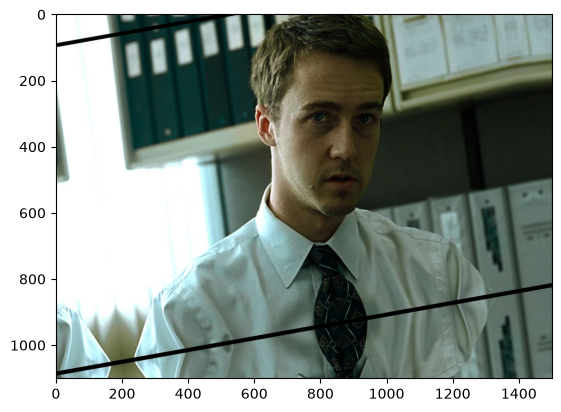

In [10]:
"""From paper:
destination image pixel
coordinate X to the source image pixel coordinate X' such that for a
line PQ in the destination image and P'Q' in the source image.
"""
AW = 1e-10 # smoothness of interpolation, larger than near zero adds guaranteed weight to destination pixels even if they land on a line
BW = 0 # relative strength of different lines falls off with distance
PW = 1 # if it is zero, then all lines have the same weight if it is one, then longer lines have a greater relative weight
h, w = pittimg.shape[:2]
# Coordinates of each pixel so we can do matmul because faster
X = np.stack(np.meshgrid(np.arange(w), np.arange(h)), -1).astype(np.float64)
DSUM = np.zeros_like(X)
wsum = np.zeros((h, w))
# Source Edward Norton, Dest Brad Pitt
# Tyler Durden!! Doesn't really work lol
for (Psrc, Qsrc), (Pdest, Qdest) in tqdm(list(zip(np.array(norton["lines"]), np.array(pitt["lines"])))):
    # calculate u,v based on Pi,Qi
    vector = Qdest-Pdest
    length = np.linalg.norm(vector)
    u = ((X-Pdest) @ vector) / length**2
    v = ((X-Pdest) @ perpendicular(vector)) / length
    
    # calculate X'i based on u,v and Pi',Qi'
    vectorP = Qsrc-Psrc
    Xprime = Psrc + u[...,None] * vectorP + v[..., None] * perpendicular(vectorP)/np.linalg.norm(vectorP)
    # Shortest distance from X to PiQi see dagger
    dist = np.abs(v) # abs(v) if 0<u<1
    dist = np.where(u < 0, np.linalg.norm(X-Pdest, axis=-1), dist) # distance from P to the point if u<0
    dist = np.where(u > 1, np.linalg.norm(X-Qdest, axis=-1), dist) # distance from Q to the point if u>1 
    weight = (length**PW/(AW+dist))**BW
    DSUM += (Xprime - X) * weight[..., None]
    wsum += weight
Xp = X + DSUM / wsum[..., None]
warped = cv2.remap(nortonimg, Xp[..., 0].astype(np.float32), Xp[..., 1].astype(np.float32),
                   cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
plt.imshow(warped)

In [ ]:
def old_warp(img, src_lines, dest_lines, AW, BW, PW):
    src_lines = np.asarray(src_lines, dtype=np.float64)
    dest_lines = np.asarray(dest_lines, dtype=np.float64)
    h, w = img.shape[:2]
    # Coordinates of each pixel so we can do matmul because faster
    X = np.stack(np.meshgrid(np.arange(w), np.arange(h)), -1).astype(np.float64)
    DSUM = np.zeros_like(X)
    wsum = np.zeros((h, w))
    for (Psrc, Qsrc), (Pdest, Qdest) in zip(src_lines, dest_lines):
        # calculate u,v based on Pi,Qi
        vector = Qdest - Pdest
        length = np.linalg.norm(vector)
        u = ((X - Pdest) @ vector) / length**2
        v = ((X - Pdest) @ perpendicular(vector)) / length

        # calculate X'i based on u,v and Pi',Qi'
        vectorP = Qsrc - Psrc
        Xprime = Psrc + u[..., None] * vectorP + v[..., None] * perpendicular(vectorP) / np.linalg.norm(vectorP)
        # Shortest distance from X to PiQi see dagger
        dist = np.abs(v)  # abs(v) if 0<u<1
        dist = np.where(u < 0, np.linalg.norm(X - Pdest, axis=-1), dist)  # distance from P to the point if u<0
        dist = np.where(u > 1, np.linalg.norm(X - Qdest, axis=-1), dist)  # distance from Q to the point if u>1
        weight = (length**PW / (AW + dist))**BW
        DSUM += (Xprime - X) * weight[..., None]
        wsum += weight
    Xp = X + DSUM / wsum[..., None]
    return cv2.remap(img, Xp[..., 0].astype(np.float32), Xp[..., 1].astype(np.float32),
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)